# TED Talks:  Data Cleaning & Exploratory Data Analysis (EDA)

In [84]:
import pandas as pd
import numpy as np

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Initial Data Inspection & Structural Profiling

In [85]:
df=pd.read_csv("ted_talks_en_cleaned.csv")
df.head(2)

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,topics_list,available_lang_list,num_topics,num_available_lang,duration_min,published_year,published_month,published_day_name,talk_age_years,event_category
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,...,"['alternative energy', 'cars', 'climate change...","['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",9,43,16.28,2006,6,Tuesday,13.84,TED Annual
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,...,"['Africa', 'Asia', 'Google', 'demo', 'economic...","['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",11,49,19.83,2006,6,Tuesday,13.84,TED Annual


In [86]:
df.columns

Index(['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations',
       'about_speakers', 'views', 'recorded_date', 'published_date', 'event',
       'native_lang', 'available_lang', 'comments', 'duration', 'topics',
       'related_talks', 'url', 'description', 'transcript', 'recorded_date_dt',
       'published_date_dt', 'topics_list', 'available_lang_list', 'num_topics',
       'num_available_lang', 'duration_min', 'published_year',
       'published_month', 'published_day_name', 'talk_age_years',
       'event_category'],
      dtype='str')

In [87]:
drop_cols=["all_speakers","occupations","about_speakers","talk_id","published_year","published_month","published_day_name","talk_age_years"]

In [88]:
df.drop(columns=drop_cols,inplace=True)

In [89]:

display_head = df.head(3)[[ 'title', 'speaker_1', 'views', 'recorded_date', 'published_date', 'event', 'duration', 'comments']]
print(display_head.to_string(index=False))

display_tail = df.tail(3)[[ 'title', 'speaker_1', 'views', 'recorded_date', 'published_date', 'event', 'duration', 'comments']]
print(display_tail.to_string(index=False))


display_sample = df.sample(3, random_state=42)[[ 'title', 'speaker_1', 'views', 'event', 'duration', 'comments']]
print(display_sample.to_string(index=False))





                          title    speaker_1    views recorded_date published_date   event  duration  comments
    Averting the climate crisis      Al Gore  3523392    2006-02-25     2006-06-27 TED2006       977     272.0
The best stats you've ever seen Hans Rosling 14501685    2006-02-22     2006-06-27 TED2006      1190     628.0
               Simplicity sells  David Pogue  1920832    2006-02-24     2006-06-27 TED2006      1286     124.0
                                           title            speaker_1  views recorded_date published_date        event  duration  comments
How "policing for profit" undermines your rights Dick M. Carpenter II 464414    2019-06-22     2020-04-28 TEDxMileHigh       774       9.0
    The electrifying speeches of Sojourner Truth    Daina Ramey Berry  56582    2020-04-28     2020-04-30       TED-Ed       257       NaN
            The most important anus in the ocean         Cella Wright      0    2020-04-30     2020-04-30       TED-Ed       281       NaN


In [90]:
schema_df = pd.DataFrame({
    'Column': df.columns,
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Inferred Dtype': df.dtypes.astype(str).values
})
#print(schema_df.to_string(index=False))
schema_df.head(6)

,Column,Non-Null Count,Null Count,Inferred Dtype
0,title,4005,0,str
1,speaker_1,4005,0,str
2,views,4005,0,int64
3,recorded_date,4004,1,str
4,published_date,4005,0,str
5,event,4005,0,str


In [91]:
df.isnull().sum()

title                    0
speaker_1                0
views                    0
recorded_date            1
published_date           0
event                    0
native_lang              0
available_lang           0
comments               655
duration                 0
topics                   0
related_talks            0
url                      0
description              0
transcript               0
recorded_date_dt         1
published_date_dt        0
topics_list              0
available_lang_list      0
num_topics               0
num_available_lang       0
duration_min             0
event_category           0
dtype: int64

In [92]:
df.dtypes

title                      str
speaker_1                  str
views                    int64
recorded_date              str
published_date             str
event                      str
native_lang                str
available_lang             str
comments               float64
duration                 int64
topics                     str
related_talks              str
url                        str
description                str
transcript                 str
recorded_date_dt           str
published_date_dt          str
topics_list                str
available_lang_list        str
num_topics               int64
num_available_lang       int64
duration_min           float64
event_category             str
dtype: object

In [93]:
df.drop(columns=["recorded_date_dt","published_date_dt","url"],inplace=True)

In [94]:
df.head()

,title,speaker_1,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,description,transcript,topics_list,available_lang_list,num_topics,num_available_lang,duration_min,event_category
0,Averting the climate crisis,Al Gore,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...","['alternative energy', 'cars', 'climate change...","['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",9,43,16.28,TED Annual
1,The best stats you've ever seen,Hans Rosling,14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...","['Africa', 'Asia', 'Google', 'demo', 'economic...","['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",11,49,19.83,TED Annual
2,Simplicity sells,David Pogue,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...","['computers', 'entertainment', 'interface desi...","['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",9,26,21.43,TED Annual
3,Greening the ghetto,Majora Carter,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,"['MacArthur grant', 'activism', 'business', 'c...","['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",9,35,18.60,TED Annual
4,Do schools kill creativity?,Sir Ken Robinson,65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,"['children', 'creativity', 'culture', 'dance',...","['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",7,62,19.40,TED Annual


In [95]:
df["recorded_date"]=df["recorded_date"].fillna(df["recorded_date"].mode()[0])

<Axes: ylabel='comments'>

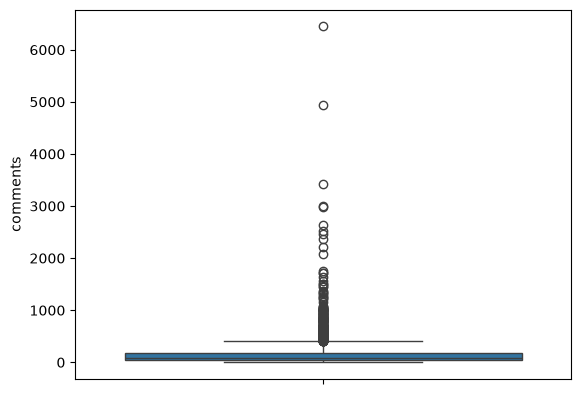

In [96]:
#df["comments"].value_counts()
import seaborn as sns
sns.boxplot(df["comments"])

In [97]:
df["comments"]=df["comments"].fillna(df["comments"].median())

In [105]:
df.isnull().sum()

title                  0
speaker_1              0
views                  0
recorded_date          0
published_date         0
event                  0
native_lang            0
available_lang         0
comments               0
duration               0
topics                 0
related_talks          0
description            0
transcript             0
topics_list            0
available_lang_list    0
num_topics             0
num_available_lang     0
duration_min           0
event_category         0
dtype: int64

---
# PHASE 2: EXPLORATORY DATA ANALYSIS (EDA)

**Analytical Question:** How are view counts distributed across the TED catalog? Is viewership normally distributed, or characterized by extreme positive skewness where a tiny fraction of talks captures the majority of views?


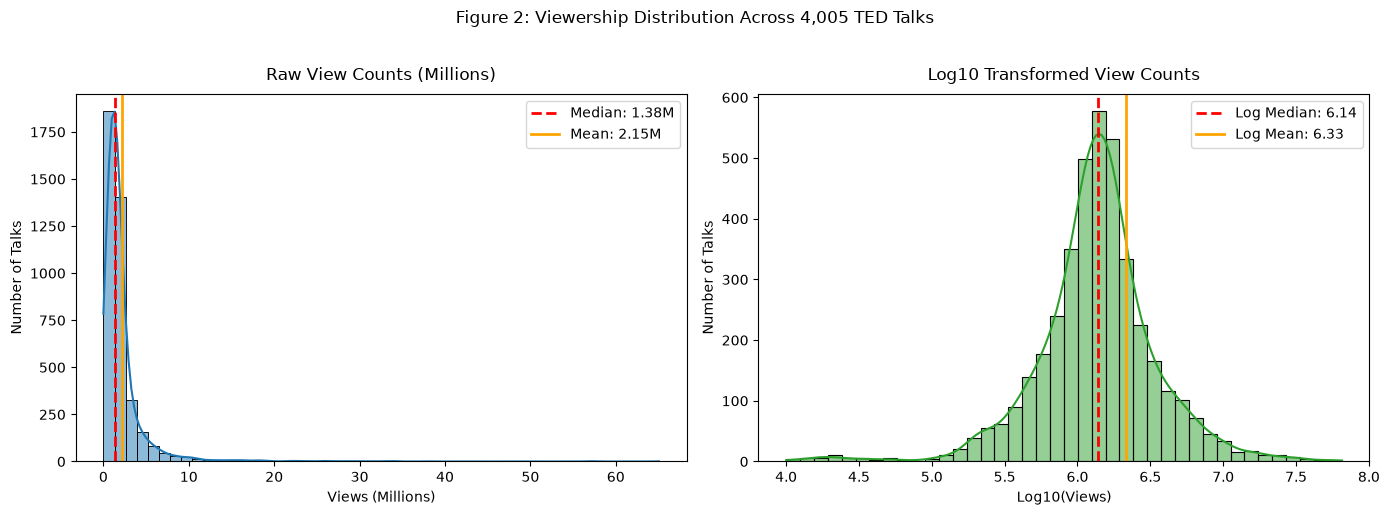

In [116]:
# Summary statistics for views
views_series = df['views']
views_mean = views_series.mean()
views_median = views_series.median()
views_std = views_series.std()
views_skew = views_series.skew()
# views_kurt = views_series.kurtosis()

# Dual-panel distribution visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Raw Views Distribution
sns.histplot(views_series / 1e6, bins=50, kde=True, ax=ax1, color='#1f77b4', edgecolor='black')
ax1.axvline(views_median / 1e6, color='red', linestyle='--', linewidth=2, label=f'Median: {views_median/1e6:.2f}M')
ax1.axvline(views_mean / 1e6, color='orange', linestyle='-', linewidth=2, label=f'Mean: {views_mean/1e6:.2f}M')
ax1.set_title('Raw View Counts (Millions)', pad=10)
ax1.set_xlabel('Views (Millions)')
ax1.set_ylabel('Number of Talks')
ax1.legend(frameon=True)

# Panel 2: Log10 Transformed Views Distribution
log_views = np.log10(views_series[views_series > 0])
sns.histplot(log_views, bins=40, kde=True, ax=ax2, color='#2ca02c', edgecolor='black')
ax2.axvline(np.log10(views_median), color='red', linestyle='--', linewidth=2, label=f'Log Median: {np.log10(views_median):.2f}')
ax2.axvline(np.log10(views_mean), color='orange', linestyle='-', linewidth=2, label=f'Log Mean: {np.log10(views_mean):.2f}')
ax2.set_title('Log10 Transformed View Counts', pad=10)
ax2.set_xlabel('Log10(Views)')
ax2.set_ylabel('Number of Talks')
ax2.legend(frameon=True)

plt.suptitle('Figure 2: Viewership Distribution Across 4,005 TED Talks', y=1.02)
plt.tight_layout()
plt.show()


In [108]:
# Top 10 Most-Viewed TED Talks of All Time
top_talks = df.nlargest(10, 'views')[['title', 'speaker_1', 'views', 'duration_min', 'event']]
print("\n" + "=" * 80)
print("TABLE 2: TOP 10 MOST-VIEWED TED TALKS OF ALL TIME")
print("=" * 80)
for i, r in top_talks.reset_index(drop=True).iterrows():
    print(f"{i+1:2d}. {r['title'][:45]:<45} | {r['speaker_1']:<20} | {r['views']/1e6:5.1f}M views | {r['duration_min']:4.1f} min ")
print("=" * 80)



TABLE 2: TOP 10 MOST-VIEWED TED TALKS OF ALL TIME
 1. Do schools kill creativity?                   | Sir Ken Robinson     |  65.1M views | 19.4 min 
 2. Your body language may shape who you are      | Amy Cuddy            |  57.1M views | 21.0 min 
 3. This is what happens when you reply to spam e | James Veitch         |  56.9M views |  9.8 min 
 4. How great leaders inspire action              | Simon Sinek          |  49.7M views | 18.1 min 
 5. The power of vulnerability                    | Brené Brown          |  47.5M views | 20.3 min 
 6. How to speak so that people want to listen    | Julian Treasure      |  41.5M views | 10.0 min 
 7. Inside the mind of a master procrastinator    | Tim Urban            |  38.0M views | 14.1 min 
 8. Looks aren't everything. Believe me, I'm a mo | Cameron Russell      |  33.9M views |  9.6 min 
 9. My philosophy for a happy life                | Sam Berns            |  33.7M views | 12.8 min 
10. The next outbreak? We're not ready           

**Analytical Question:** How closely do TED talks adhere to the famous "18-minute rule"? How has the emergence of short educational animations (TED-Ed) shaped the duration distribution?


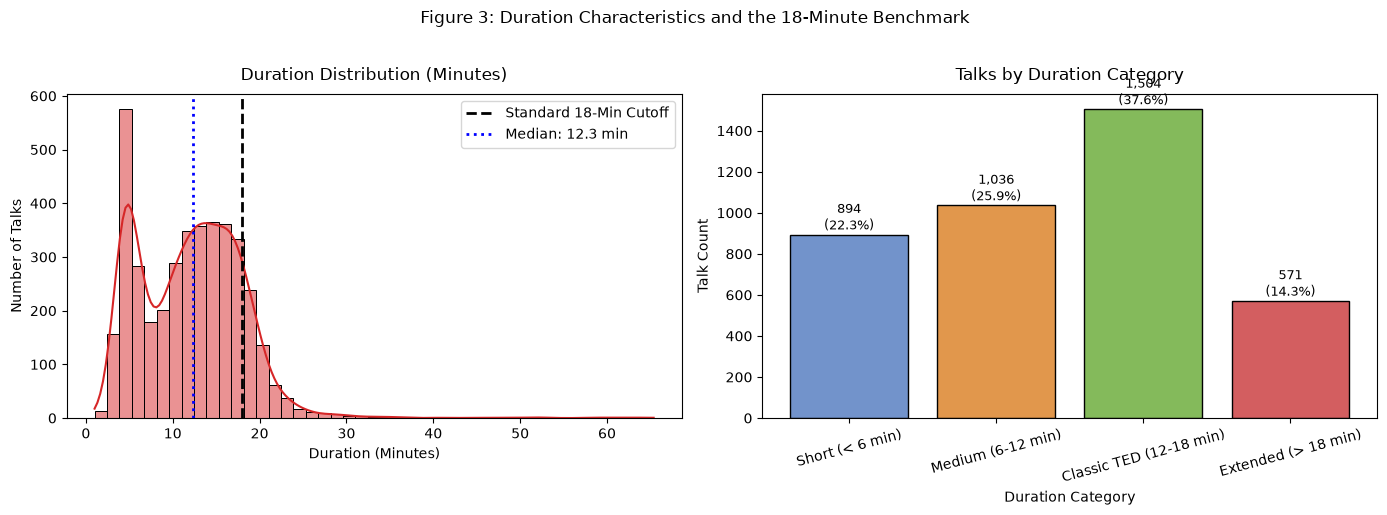

In [118]:
dur_series = df['duration_min']

# Distribution Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with 18-minute cutoff marker
sns.histplot(dur_series, bins=45, kde=True, ax=ax1, color='#d62728', edgecolor='black')
ax1.axvline(18.0, color='black', linestyle='--', linewidth=2, label='Standard 18-Min Cutoff')
ax1.axvline(dur_series.median(), color='blue', linestyle=':', linewidth=2, label=f'Median: {dur_series.median():.1f} min')
ax1.set_title('Duration Distribution (Minutes)', pad=10)
ax1.set_xlabel('Duration (Minutes)')
ax1.set_ylabel('Number of Talks')
ax1.legend(frameon=True)

# Categorical Breakdown by Length Tiers
df['duration_tier'] = pd.cut(
    df['duration_min'],
    bins=[0, 6, 12, 18, 100],
    labels=['Short (< 6 min)', 'Medium (6-12 min)', 'Classic TED (12-18 min)', 'Extended (> 18 min)']
)
tier_counts = df['duration_tier'].value_counts(sort=False)
bars = ax2.bar(tier_counts.index.astype(str), tier_counts.values, color=['#7293cb', '#e1974c', '#84ba5b', '#d35e60'], edgecolor='black')
ax2.set_title('Talks by Duration Category', pad=10)
ax2.set_xlabel('Duration Category')
ax2.set_ylabel('Talk Count')
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=15)

for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 25, f"{h:,}\n({h/len(df)*100:.1f}%)", ha='center', fontsize=9)

plt.suptitle('Figure 3: Duration Characteristics and the 18-Minute Benchmark', y=1.02)
plt.tight_layout()
plt.show()


**Analytical Question:** How actively do viewers comment on talks, and what does the comments-per-view ratio tell us about audience provocation versus passive entertainment?


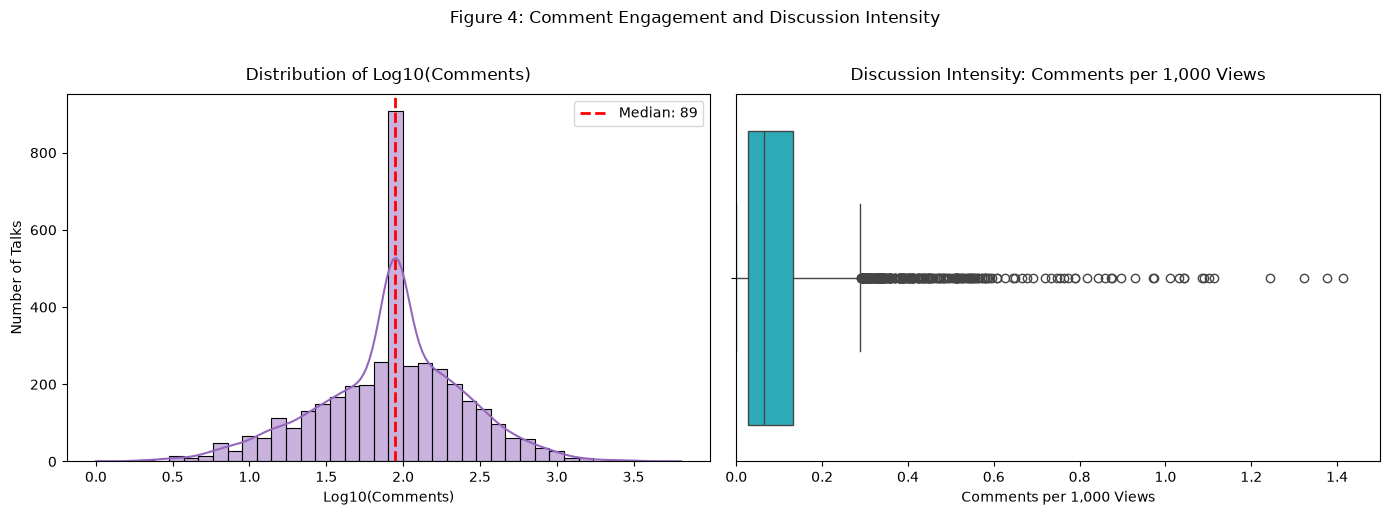

In [124]:
comments_clean = df['comments'].dropna()


# Discussion Ratio: Comments per 1,000 views
df['comments_per_1k_views'] = np.where((df['views'] > 0) & df['comments'].notnull(),(df['comments'] / df['views']) * 1000,np.nan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Log10(Comments)
sns.histplot(np.log10(comments_clean[comments_clean > 0]), bins=40, kde=True, ax=ax1, color='#9467bd', edgecolor='black')
ax1.axvline(np.log10(comments_clean.median()), color='red', linestyle='--', linewidth=2, label=f'Median: {comments_clean.median():.0f}')
ax1.set_title('Distribution of Log10(Comments)', pad=10)
ax1.set_xlabel('Log10(Comments)')
ax1.set_ylabel('Number of Talks')
ax1.legend(frameon=True)

# Panel 2: Comments per 1,000 views distribution
valid_ratio = df['comments_per_1k_views'].dropna()
sns.boxplot(x=valid_ratio, ax=ax2, color='#17becf')
ax2.set_title('Discussion Intensity: Comments per 1,000 Views', pad=10)
ax2.set_xlabel('Comments per 1,000 Views')
ax2.set_xlim(0, 1.5) # Zoom in to interquartile range for visibility

plt.suptitle('Figure 4: Comment Engagement and Discussion Intensity', y=1.02)
plt.tight_layout()
plt.show()


In [123]:
# Top 5 Highest Discussion-Ratio Talks
top_debated = df.dropna(subset=['comments_per_1k_views']).nlargest(5, 'comments_per_1k_views')[['title', 'speaker_1', 'views', 'comments', 'comments_per_1k_views']]
print("\n" + "=" * 80)
print("TABLE 3: TOP 5 TALKS WITH HIGHEST DISCUSSION RATIO (COMMENTS PER 1,000 VIEWS)")
print("=" * 80)
for _, r in top_debated.iterrows():
    print(f"Title:     {r['title']}")
    print(f"Speaker:   {r['speaker_1']} | Views: {r['views']:,} | Comments: {int(r['comments']):,} | Ratio: {r['comments_per_1k_views']:.2f})")
    print("-" * 80)


TABLE 3: TOP 5 TALKS WITH HIGHEST DISCUSSION RATIO (COMMENTS PER 1,000 VIEWS)
Title:     Undocumented lives, inside out
Speaker:   JR | Views: 10,004 | Comments: 89 | Ratio: 8.90)
--------------------------------------------------------------------------------
Title:     "Illusions for a better society"
Speaker:   Aaron Duffy | Views: 10,356 | Comments: 89 | Ratio: 8.59)
--------------------------------------------------------------------------------
Title:     Humanity at the intersection of science and archaeology
Speaker:   Alisa Kazarina | Views: 10,680 | Comments: 89 | Ratio: 8.33)
--------------------------------------------------------------------------------
Title:     Community health heroes
Speaker:   Raj Panjabi | Views: 12,017 | Comments: 89 | Ratio: 7.41)
--------------------------------------------------------------------------------
Title:     When goods cross borders, armies stay home
Speaker:   Romaine Seguin | Views: 13,933 | Comments: 89 | Ratio: 6.39)
-------------


**Analytical Question:** How many topic tags are assigned to each talk, and into how many languages are talks translated through the TED Open Translation Project?


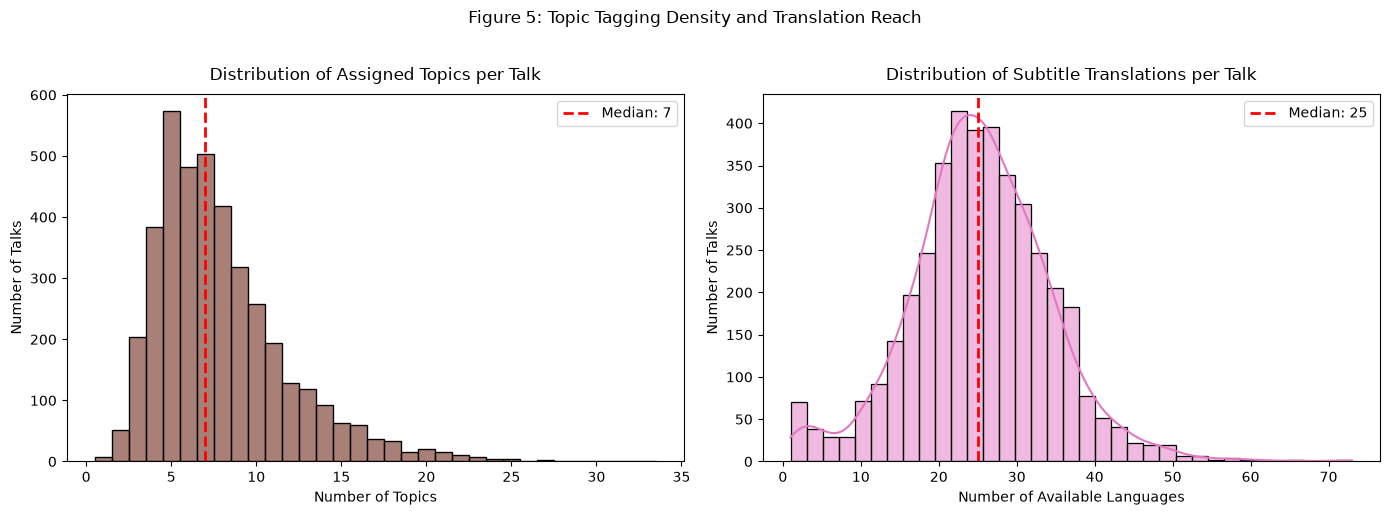

Topics per Talk:      Median = 7, Mean = 7.92, Range = [1 to 33]
Available Languages:  Median = 25, Mean = 25.30, Range = [1 to 73]


In [125]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Topics Count Distribution
sns.histplot(df['num_topics'], bins=25, discrete=True, ax=ax1, color='#8c564b', edgecolor='black')
ax1.axvline(df['num_topics'].median(), color='red', linestyle='--', linewidth=2, label=f"Median: {df['num_topics'].median():.0f}")
ax1.set_title('Distribution of Assigned Topics per Talk', pad=10)
ax1.set_xlabel('Number of Topics')
ax1.set_ylabel('Number of Talks')
ax1.legend(frameon=True)

# Available Languages Count Distribution
sns.histplot(df['num_available_lang'], bins=35, kde=True, ax=ax2, color='#e377c2', edgecolor='black')
ax2.axvline(df['num_available_lang'].median(), color='red', linestyle='--', linewidth=2, label=f"Median: {df['num_available_lang'].median():.0f}")
ax2.set_title('Distribution of Subtitle Translations per Talk', pad=10)
ax2.set_xlabel('Number of Available Languages')
ax2.set_ylabel('Number of Talks')
ax2.legend(frameon=True)

plt.suptitle('Figure 5: Topic Tagging Density and Translation Reach', y=1.02)
plt.tight_layout()
plt.show()

print(f"Topics per Talk:      Median = {df['num_topics'].median():.0f}, Mean = {df['num_topics'].mean():.2f}, Range = [{df['num_topics'].min()} to {df['num_topics'].max()}]")
print(f"Available Languages:  Median = {df['num_available_lang'].median():.0f}, Mean = {df['num_available_lang'].mean():.2f}, Range = [{df['num_available_lang'].min()} to {df['num_available_lang'].max()}]")


**Analytical Question:** Who are the most prolific speakers in the TED corpus, and how does frequency divide between institutional educators and recurring conference speakers?


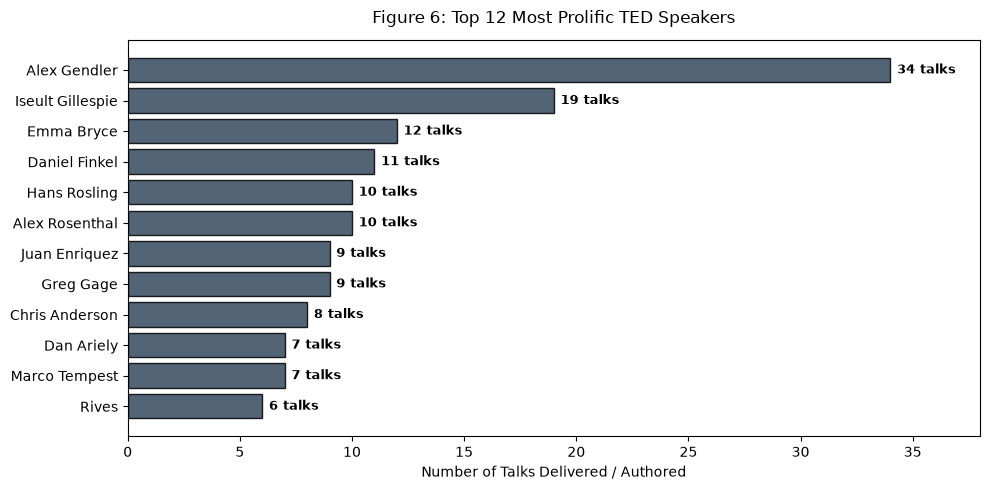

Top 5 Most Prolific Speakers:
  Alex Gendler        : 34 talks
  Iseult Gillespie    : 19 talks
  Emma Bryce          : 12 talks
  Daniel Finkel       : 11 talks
  Hans Rosling        : 10 talks


In [126]:
top_speakers = df['speaker_1'].value_counts().head(12)

fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(top_speakers))
bars = ax.barh(y_pos, top_speakers.values, color='#34495e', edgecolor='black', alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels(top_speakers.index)
ax.invert_yaxis()
ax.set_xlabel('Number of Talks Delivered / Authored')
ax.set_title('Figure 6: Top 12 Most Prolific TED Speakers', pad=12)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height()/2, f"{int(w)} talks", va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, max(top_speakers.values) + 4)
plt.tight_layout()
plt.show()

print("Top 5 Most Prolific Speakers:")
for spk, cnt in top_speakers.head(5).items():
    print(f"  {spk:<20}: {cnt} talks")



**Analytical Question:** How is the talk catalog divided across organizational tiers (TED Annual vs. TEDx vs. TED-Ed vs. TEDGlobal)?


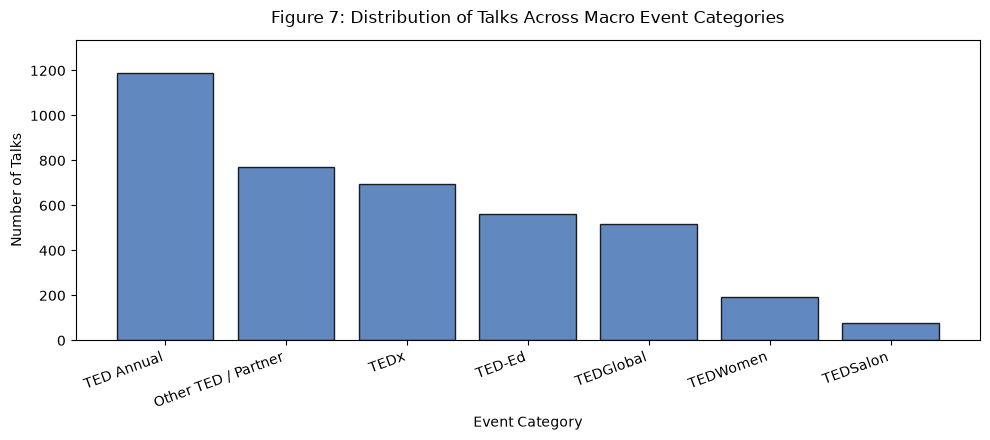

In [ ]:
event_cat_counts = df['event_category'].value_counts()

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(event_cat_counts.index, event_cat_counts.values, color='#4575b4', edgecolor='black', alpha=0.85)
ax.set_title('Figure 7: Distribution of Talks Across Macro Event Categories', pad=12)
ax.set_xlabel('Event Category')


In [ ]:
ax.set_ylabel('Number of Talks')
plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right')

# for bar in bars:
#     h = bar.get_height()
#     pct = (h / len(df) )* 100
#     ax.text(bar.get_x() + bar.get_width()/2, h + 25, f"{h:,}\n({pct:.1f}%)", ha='center', fontsize=9, fontweight='bold')

ax.set_ylim(0, max(event_cat_counts.values) + 150)
plt.tight_layout()
plt.show()



**Analytical Question:** What subjects dominate the TED corpus? Are talks evenly balanced across academic disciplines or heavily weighted toward specific domains?


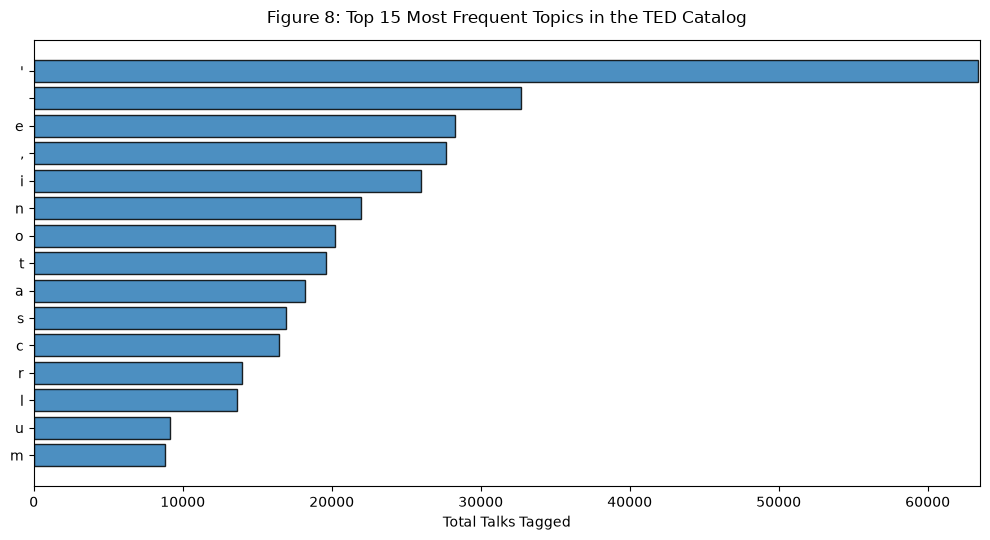

In [131]:
from collections import Counter

all_topics = [t for sublist in df['topics_list'] for t in sublist]
topic_counts = Counter(all_topics).most_common(15)
topic_df = pd.DataFrame(topic_counts, columns=['Topic', 'Count'])

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(topic_df['Topic'][::-1], topic_df['Count'][::-1], color='#2c7bb6', edgecolor='black', alpha=0.85)
ax.set_xlabel('Total Talks Tagged')
ax.set_title('Figure 8: Top 15 Most Frequent Topics in the TED Catalog', pad=12)

# for bar in bars:
#     w = bar.get_width()
#     ax.text(w + 10, bar.get_y() + bar.get_height()/2, f"{int(w):,}", va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, max(topic_df['Count']) + 120)
plt.tight_layout()
plt.show()


### 10.6 Temporal Dynamics: Catalog Expansion, Seasonality, and Lifecycle
**Analytical Question:** How has TED's publication output evolved from 2006 to 2020? What publishing schedules (day-of-week) are favored, and how does talk age correlate with viewership?


In [133]:
df.columns

Index(['title', 'speaker_1', 'views', 'recorded_date', 'published_date',
       'event', 'native_lang', 'available_lang', 'comments', 'duration',
       'topics', 'related_talks', 'description', 'transcript', 'topics_list',
       'available_lang_list', 'num_topics', 'num_available_lang',
       'duration_min', 'event_category', 'duration_tier',
       'comments_per_1k_views'],
      dtype='str')

In [143]:
df["published_date"]=pd.to_datetime(df["published_date"])
df["published_year"]=df["published_date"].dt.year
df["published_day_name"]=df["published_date"].dt.day

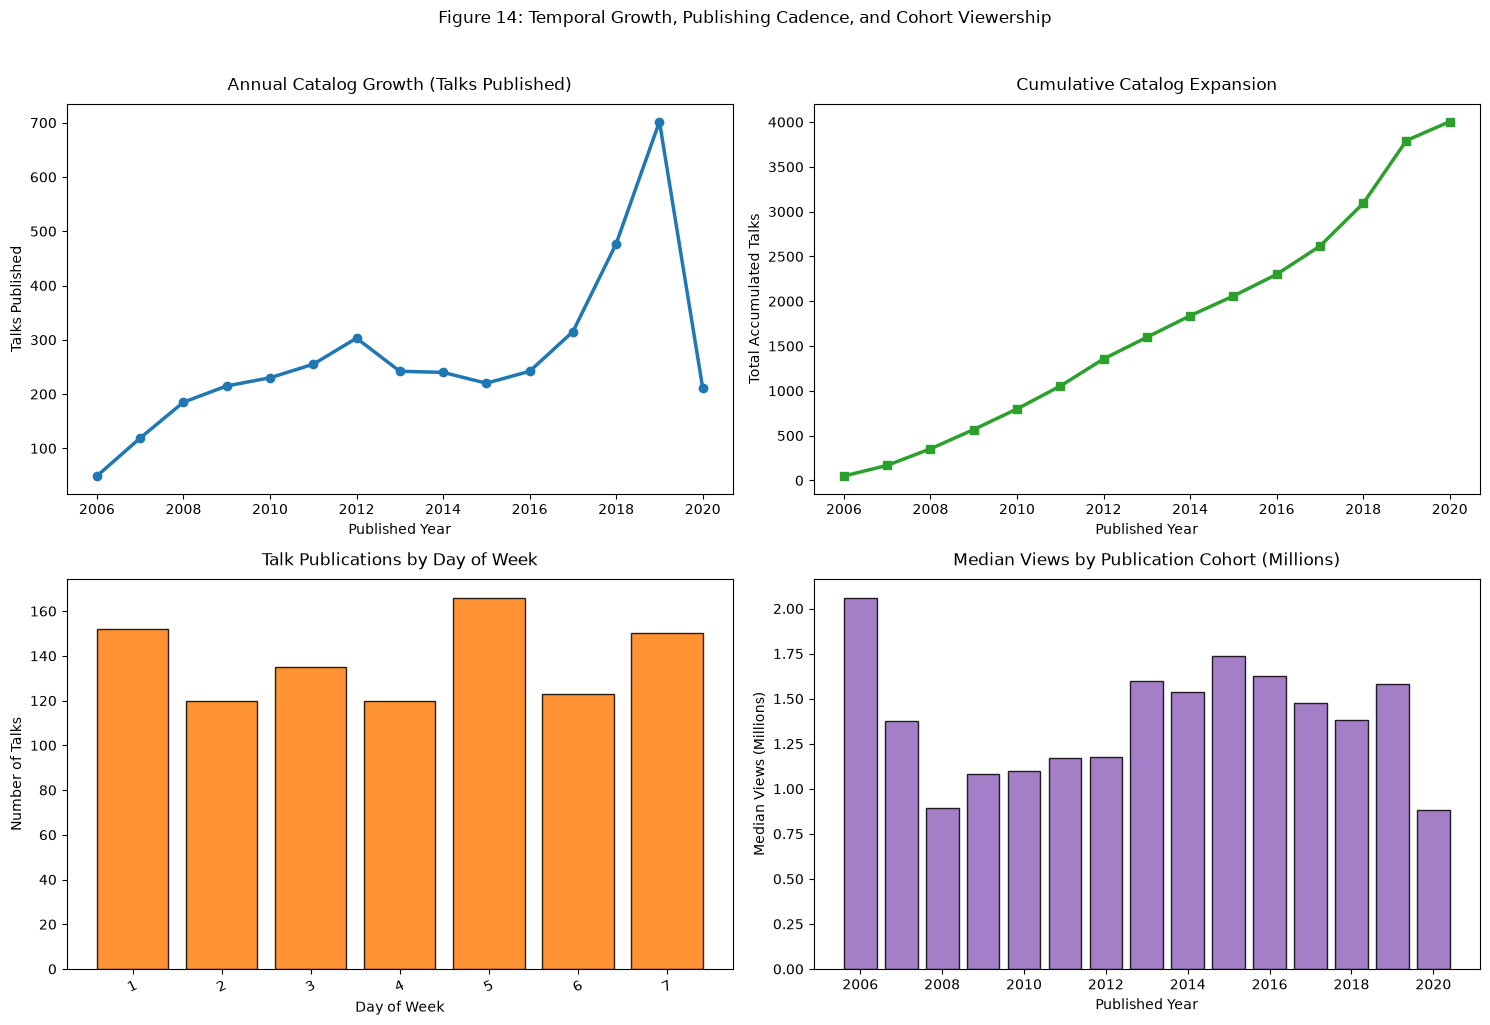

In [145]:
fig, axes = plt.subplots(2,2, figsize=(15, 10))

# 1. Talks Published per Year
yearly_counts = df['published_year'].value_counts().sort_index()
axes[0, 0].plot(yearly_counts.index, yearly_counts.values, marker='o', color='#1f77b4', linewidth=2.5)
axes[0, 0].set_title('Annual Catalog Growth (Talks Published)', pad=10)
axes[0, 0].set_xlabel('Published Year')
axes[0, 0].set_ylabel('Talks Published')

# 2. Cumulative Catalog Volume
axes[0, 1].plot(yearly_counts.index, yearly_counts.cumsum(), marker='s', color='#2ca02c', linewidth=2.5)
axes[0, 1].set_title('Cumulative Catalog Expansion', pad=10)
axes[0, 1].set_xlabel('Published Year')
axes[0, 1].set_ylabel('Total Accumulated Talks')

# 3. Day of Week Publication Pattern
dow_order =[1,2,3,4,5,6,7]
dow_counts = df['published_day_name'].value_counts().reindex(dow_order)
axes[1, 0].bar(dow_counts.index, dow_counts.values, color='#ff7f0e', edgecolor='black', alpha=0.85)
axes[1, 0].set_title('Talk Publications by Day of Week', pad=10)
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('Number of Talks')
plt.setp(axes[1, 0].xaxis.get_majorticklabels(), rotation=25)

# 4. Median Views by Publication Cohort
yearly_median_views = df.groupby('published_year')['views'].median() / 1e6
axes[1, 1].bar(yearly_median_views.index, yearly_median_views.values, color='#9467bd', edgecolor='black', alpha=0.85)
axes[1, 1].set_title('Median Views by Publication Cohort (Millions)', pad=10)
axes[1, 1].set_xlabel('Published Year')
axes[1, 1].set_ylabel('Median Views (Millions)')

plt.suptitle('Figure 14: Temporal Growth, Publishing Cadence, and Cohort Viewership', y=1.02)
plt.tight_layout()
plt.show()



**Analytical Question:** What linear and rank relationships exist across all numerical attributes (views, comments, duration, translation languages, topics, and publication time)?


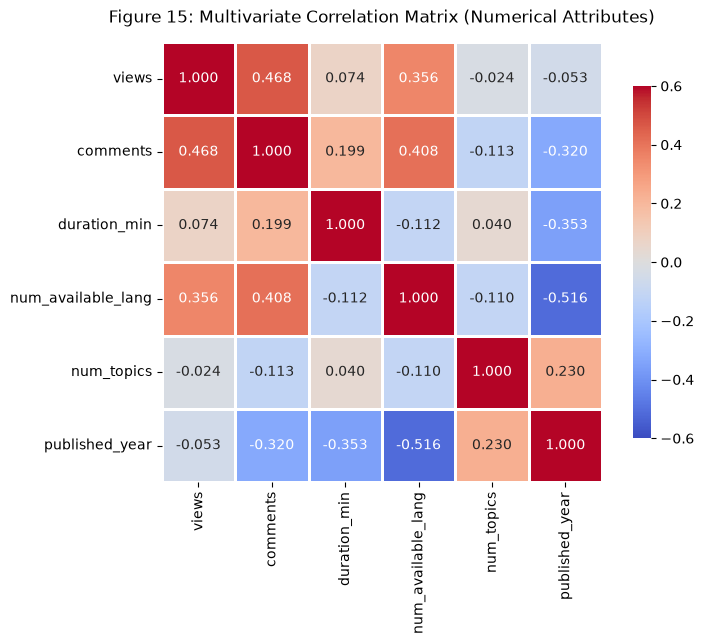

In [148]:
num_cols = ['views', 'comments', 'duration_min', 'num_available_lang', 'num_topics', 'published_year']
clean_num_subset = df[num_cols].dropna()

corr_matrix = clean_num_subset.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_matrix,annot=True,fmt='.3f',cmap='coolwarm',vmin=-0.6,vmax=0.6,center=0,square=True,linewidths=0.8,cbar_kws={'shrink': 0.8},ax=ax)

ax.set_title('Figure 15: Multivariate Correlation Matrix (Numerical Attributes)', pad=14)
plt.tight_layout()
plt.show()

